# Stacked Generalization: Stacking и Blending

Практическая часть доклада. План:

1. Данные: цены на жильё (California Housing, 20 640 строк).
2. Stacking с out-of-fold предсказаниями на собственной реализации `stacking_lib`.
3. Blending на отложенной выборке (holdout).
4. Почему нельзя учить мета-модель на предсказаниях train: демонстрация утечки.
5. Сводка по нескольким разбиениям, размер holdout, состав пула моделей, классификация.

Тяжёлые многосидовые прогоны считает `scripts/run_experiments.py` и `scripts/run_ablation.py`
(результаты в `results/`). Здесь один сид показан пошагово, остальное читается из JSON.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from stacking_lib import Stacking, Blending
from stacking_lib.data import load_housing
from stacking_lib.models import make_base_models, make_meta_nnls

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
rmse = lambda y, p: float(np.sqrt(mean_squared_error(y, p)))
SEED = 0

## 1. Данные

In [2]:
X, y = load_housing()
print(X.shape)
X.head()

(20640, 16)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_<1H OCEAN,ocean_INLAND,ocean_ISLAND,ocean_NEAR BAY,ocean_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,6.984127,0.146591,2.555556,0.0,0.0,0.0,1.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,6.238137,0.155797,2.109842,0.0,0.0,0.0,1.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,8.288136,0.129516,2.802260,0.0,0.0,0.0,1.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,5.817352,0.184458,2.547945,0.0,0.0,0.0,1.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,6.281853,0.172096,2.181467,0.0,0.0,0.0,1.0,0.0


Целевая переменная - медианная цена дома в квартале (`median_house_value`, доллары).
К исходным признакам добавлены три отношения (комнат на домохозяйство и т. п.)
и one-hot для `ocean_proximity`. Пропуски (`total_bedrooms`) заполняются медианой
внутри пайплайнов моделей, поэтому утечки из test нет.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
y_tr, y_te = y_tr.to_numpy(), y_te.to_numpy()
print(len(X_tr), len(X_te))
print("Базовые модели:", [n for n, _ in make_base_models()])

16512 4128
Базовые модели: ['ridge', 'knn', 'rf', 'et', 'hgb']


## 2. Stacking (OOF, K = 5)

`Stacking.fit` делает ровно то, что описано в докладе: для каждой модели и каждого из 5 фолдов
обучает её на 4 фолдах и предсказывает пятый, собирая матрицу OOF-предсказаний `oof_`
(размер `n_train x 5`). Мета-модель - линейная регрессия с неотрицательными весами.
После этого базовые модели переобучаются на всём train. Обучение занимает пару минут.

In [4]:
stack = Stacking(make_base_models(SEED), make_meta_nnls(), n_splits=5, random_state=SEED)
stack.fit(X_tr, y_tr)
names = [n for n, _ in stack.base_models_]
print("OOF-матрица:", stack.oof_.shape)
pd.DataFrame(stack.oof_[:5], columns=names).round(0)

OOF-матрица: (16512, 5)


,ridge,knn,rf,et,hgb
0,146853.0,152057.0,210997.0,211989.0,261870.0
1,276348.0,303521.0,264592.0,286521.0,252611.0
2,219414.0,215629.0,202249.0,211203.0,208525.0
3,139999.0,129073.0,127066.0,118482.0,114366.0
4,248379.0,264094.0,329043.0,292175.0,351461.0


In [5]:
P_te = stack.base_predictions(X_te)          # предсказания базовых моделей на test
rows = {n: {"RMSE test": rmse(y_te, P_te[:, i]), "R2 test": r2_score(y_te, P_te[:, i])}
        for i, n in enumerate(names)}
rows["среднее по моделям"] = {"RMSE test": rmse(y_te, P_te.mean(axis=1)),
                              "R2 test": r2_score(y_te, P_te.mean(axis=1))}
rows["STACKING (NNLS)"] = {"RMSE test": rmse(y_te, stack.predict(X_te)),
                           "R2 test": r2_score(y_te, stack.predict(X_te))}
res = pd.DataFrame(rows).T.round(3)
res

,RMSE test,R2 test
ridge,67951.618,0.646
knn,60100.210,0.723
rf,48236.869,0.822
et,48909.808,0.817
hgb,43400.531,0.856
среднее по моделям,49749.537,0.810
STACKING (NNLS),43467.574,0.855


In [6]:
w = pd.Series(stack.meta_weights_)
print("Веса мета-модели:\n", w.round(3).to_string())
print("Сумма весов:", round(w.sum(), 3), "| intercept:", round(stack.meta_model_.intercept_))

Веса мета-модели:
 ridge    0.000
knn      0.000
rf       0.016
et       0.130
hgb      0.865
Сумма весов: 1.012 | intercept: -2555


Мета-модель почти целиком опирается на градиентный бустинг (`hgb`) и чуть-чуть на `et`;
линейная модель и KNN получили нулевой вес. Это значит: в этом пуле одна модель заметно сильнее остальных,
и стекингу почти нечего добавлять к ней (см. абляцию ниже).

## 3. Blending (holdout 20 %)

In [7]:
blend = Blending(make_base_models(SEED), make_meta_nnls(), holdout_size=0.2, random_state=SEED)
blend.fit(X_tr, y_tr)
print("Мета-признаки строятся на", blend.holdout_features_.shape[0], "объектах holdout")
print("RMSE blending:", round(rmse(y_te, blend.predict(X_te))))
print("RMSE stacking:", round(rmse(y_te, stack.predict(X_te))))
print({k: round(v, 3) for k, v in blend.meta_weights_.items()})

Мета-признаки строятся на 3303 объектах holdout


RMSE blending: 44692


RMSE stacking: 43468
{'ridge': 0.0, 'knn': 0.0, 'rf': 0.0, 'et': 0.097, 'hgb': 0.916}


Blending проще (одно обучение каждой модели) и не требует K-кратного пересчёта, но платит двумя вещами:
базовые модели видят только 80 % train, а мета-модель - только 20 % (3 300 объектов).

## 4. Проверка корректности: наша реализация против `sklearn.ensemble.StackingRegressor`
Те же базовые модели, те же фолды (`KFold(5, shuffle=True, random_state=0)`), тот же мета-алгоритм.
Расчёт сделан в `run_experiments.py` (сид 0), здесь читаем итог.

In [8]:
R = json.loads((ROOT / "results" / "metrics.json").read_text())
p0 = R["per_seed"][0]
print("sklearn StackingRegressor RMSE:", round(p0["sklearn_stacking"]["rmse"]))
print("Наш Stacking RMSE:            ", round(p0["stacking_nnls"]["rmse"]))
print("Макс. |разница предсказаний|:  ", p0["sklearn_vs_ours_max_abs_diff"])

sklearn StackingRegressor RMSE: 43468
Наш Stacking RMSE:             43468
Макс. |разница предсказаний|:   0.0


## 5. Утечка данных: мета-модель на предсказаниях train

Самая частая ошибка: обучить базовые модели на train, предсказать ими же train и на этих предсказаниях учить мета-модель.
Сравним RMSE каждой модели на train (in-sample), в OOF и на test.

In [9]:
P_tr = stack.base_predictions(X_tr)          # in-sample предсказания
gap = pd.DataFrame({
    "train (in-sample)": [rmse(y_tr, P_tr[:, i]) for i in range(len(names))],
    "OOF": [rmse(y_tr, stack.oof_[:, i]) for i in range(len(names))],
    "test": [rmse(y_te, P_te[:, i]) for i in range(len(names))]}, index=names).round(0)
gap

,train (in-sample),OOF,test
ridge,67923.0,68260.0,67952.0
knn,0.0,60011.0,60100.0
rf,23939.0,49409.0,48237.0
et,18178.0,50131.0,48910.0
hgb,33435.0,46476.0,43401.0


In [10]:
leaky_meta = make_meta_nnls().fit(P_tr, y_tr)           # ОШИБКА: мета на in-sample
print("Веса (утечка):", dict(zip(names, leaky_meta.coef_.round(3))))
print("RMSE на train мета-модели:", round(rmse(y_tr, leaky_meta.predict(P_tr))))
print("RMSE на test (утечка):    ", round(rmse(y_te, leaky_meta.predict(P_te))))
print("RMSE на test (OOF, верно):", round(rmse(y_te, stack.predict(X_te))))

Веса (утечка): {'ridge': np.float64(0.0), 'knn': np.float64(1.0), 'rf': np.float64(0.0), 'et': np.float64(0.0), 'hgb': np.float64(0.0)}
RMSE на train мета-модели: 0
RMSE на test (утечка):     60100


RMSE на test (OOF, верно): 43468


KNN с `weights="distance"` запоминает train (ошибка на train равна нулю), поэтому «наивная» мета-модель
отдаёт ему вес 1 и игнорирует остальные: на train выглядит идеально, на test получается RMSE KNN (около 60 тыс.),
то есть хуже любого леса и бустинга. OOF-предсказания честные, поэтому мета-модель правильно оценивает, кому доверять.

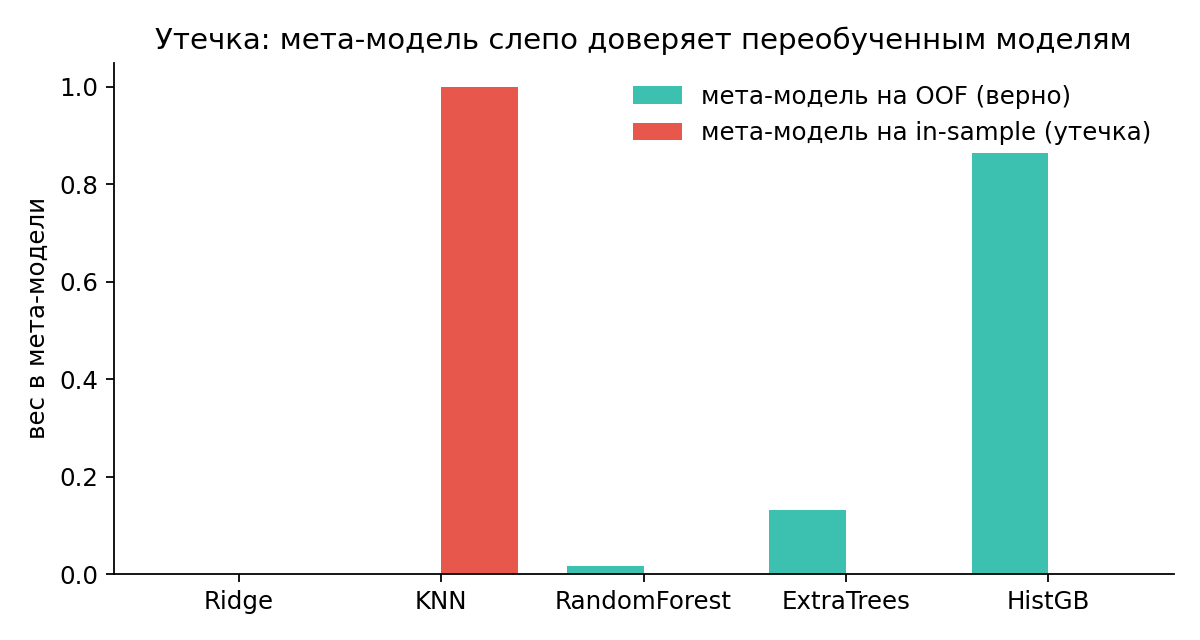

In [11]:
display(Image(str(ROOT / 'docs' / 'figures' / 'fig_weights_leakage.png')))

## 6. Разнообразие моделей

In [12]:
C_ = np.corrcoef((stack.oof_ - y_tr[:, None]).T)
pd.DataFrame(C_, index=names, columns=names).round(2)

,ridge,knn,rf,et,hgb
ridge,1.00,0.80,0.77,0.80,0.69
knn,0.80,1.00,0.84,0.89,0.77
rf,0.77,0.84,1.00,0.96,0.92
et,0.80,0.89,0.96,1.00,0.90
hgb,0.69,0.77,0.92,0.90,1.00


Ошибки `rf` и `et` коррелируют на 0.96: это почти копии друг друга, поэтому вместе они дают мало.
Самая «непохожая» на остальных - линейная модель, но она слишком слабая, чтобы получить вес.
Потенциал стекинга определяется не числом моделей, а тем, насколько их ошибки различаются при сопоставимом качестве.

## 7. Сводка по трём разбиениям (сиды 0, 1, 2)

In [13]:
S = R["summary"]
order = ["ridge", "knn", "rf", "et", "hgb", "mean_ensemble", "blending_0.2",
         "stacking_ridge", "stacking_hgb", "stacking_nnls"]
tbl = pd.DataFrame({k: {"RMSE": f"{S[k]['rmse'][0]:.0f} ± {S[k]['rmse'][1]:.0f}",
                        "MAE": f"{S[k]['mae'][0]:.0f}",
                        "R2": f"{S[k]['r2'][0]:.4f}"} for k in order}).T
tbl

,RMSE,MAE,R2
ridge,68251 ± 216,49098,0.6473
knn,59934 ± 784,40209,0.7280
rf,48544 ± 263,31856,0.8216
et,49341 ± 308,32573,0.8157
hgb,44519 ± 791,29355,0.8499
mean_ensemble,50112 ± 268,33737,0.8099
blending_0.2,45668 ± 693,30260,0.8421
stacking_ridge,44469 ± 803,29176,0.8503
stacking_hgb,44650 ± 982,29168,0.8490
stacking_nnls,44544 ± 762,29264,0.8498


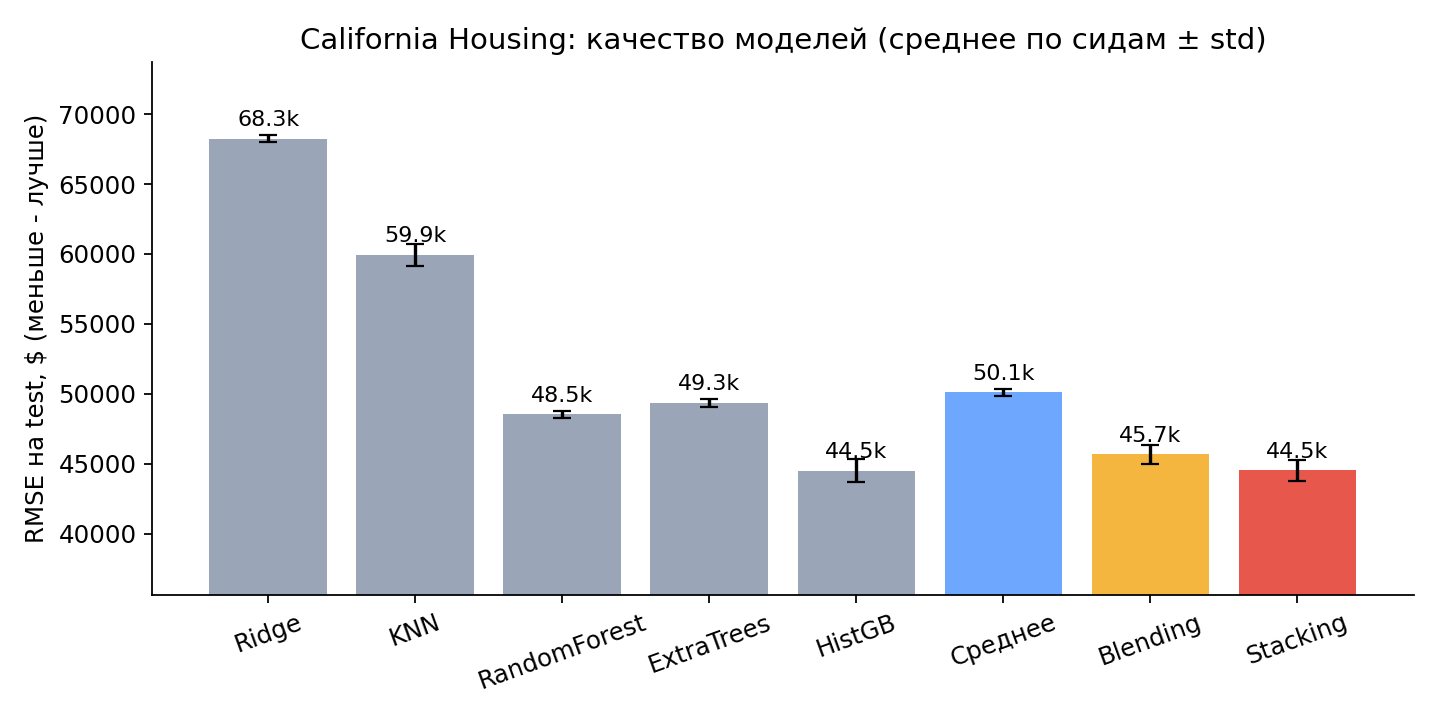

In [14]:
display(Image(str(ROOT / 'docs' / 'figures' / 'fig_rmse_comparison.png')))

**Наблюдения.**
* Stacking (44.5 тыс.) практически равен лучшей одиночной модели HistGB (44.5 тыс.): разница в пределах шума между разбиениями.
* Простое среднее (50.1 тыс.) хуже лучшей модели: слабые Ridge и KNN тянут его вниз. Обучаемые веса это исправляют.
* Blending (45.7 тыс.) стабильно хуже stacking: меньше данных у базовых моделей и у мета-модели.
* Выбор мета-модели (NNLS, Ridge, HistGB) почти не влияет: различия порядка 100-200 долларов.

## 8. Размер holdout в blending

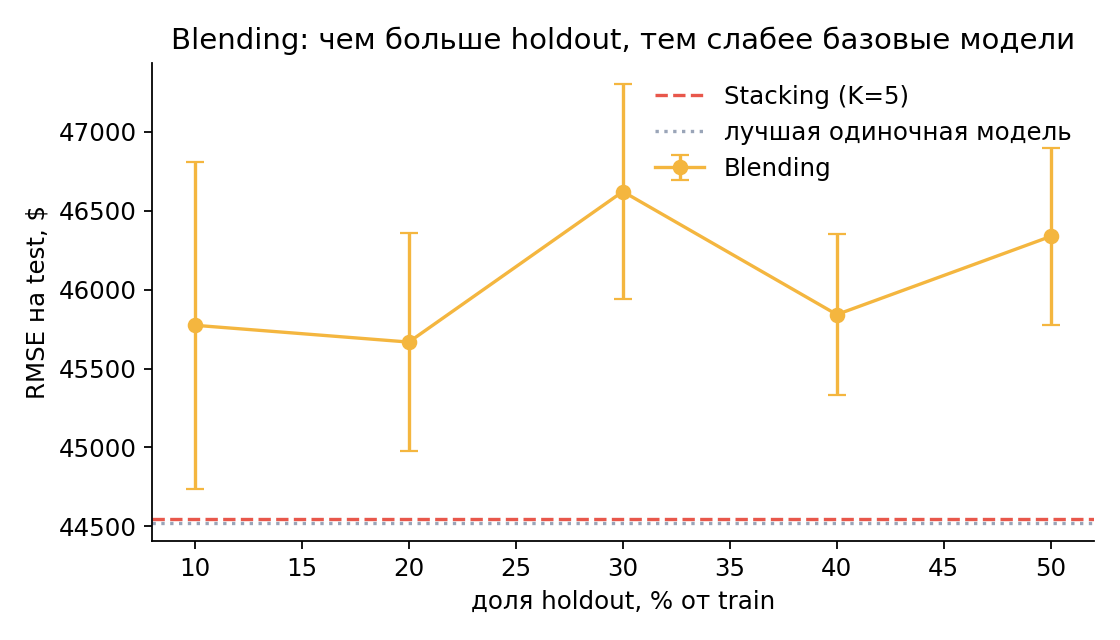

In [15]:
display(Image(str(ROOT / 'docs' / 'figures' / 'fig_blend_holdout.png')))

Зависимость слабая и шумная: на отрезке 10-50 % RMSE колеблется в пределах 45.7-46.6 тыс. и остаётся хуже stacking.
Это отражает компромисс: больший holdout даёт мета-модели больше данных, но обедняет базовые модели.

## 9. Когда стекинг помогает: состав пула моделей

In [16]:
A = json.loads((ROOT / "results" / "ablation.json").read_text())
abl = pd.DataFrame({pool: {"Stacking RMSE": np.mean(v["stack"]),
                           "лучшая одиночная": np.mean(v["best_single"]),
                           "кто лучший": v["best_name"][0]} for pool, v in A.items()}).T
abl["выигрыш, %"] = ((1 - abl["Stacking RMSE"].astype(float) / abl["лучшая одиночная"].astype(float)) * 100).round(2)
abl[["Stacking RMSE", "лучшая одиночная"]] = abl[["Stacking RMSE", "лучшая одиночная"]].astype(float).round(0)
abl

,Stacking RMSE,лучшая одиночная,кто лучший,"выигрыш, %"
все 5 моделей,44544.0,44519.0,hgb,-0.06
без HistGB,48255.0,48544.0,rf,0.60
только деревья,44544.0,44519.0,hgb,-0.06
RF + KNN,48429.0,48544.0,rf,0.24
RF + ET (похожие),48255.0,48544.0,rf,0.60


Даже в лучшем случае выигрыш небольшой: без HistGB stacking даёт 48.3 тыс. против 48.5 тыс. у лучшей одиночной модели (RF), то есть около 0.6 %.
Пул из RF и KNN даёт около 0.2 %. Когда в пуле есть HistGB, выигрыш практически нулевой: ему достаётся почти весь вес.
Заметный прирост от стекинга на этих данных ожидать не стоит; его ценность здесь - не нужно вручную выбирать лучшую модель и можно безопасно добавлять новые.

## 10. Классификация (breast cancer, 5-fold x 2 повтора)

In [17]:
cl = pd.DataFrame(R["classification"]).T
cl["logloss"] = cl.apply(lambda r: f"{r.log_loss_mean:.3f} ± {r.log_loss_std:.3f}", axis=1)
cl["accuracy"] = cl.apply(lambda r: f"{r.acc_mean:.3f} ± {r.acc_std:.3f}", axis=1)
cl[["logloss", "accuracy"]]

,logloss,accuracy
lr,0.074 ± 0.032,0.975 ± 0.018
svm,0.083 ± 0.036,0.974 ± 0.011
knn,0.167 ± 0.080,0.966 ± 0.020
rf,0.126 ± 0.033,0.962 ± 0.013
nb,0.457 ± 0.167,0.937 ± 0.025
mean_proba,0.094 ± 0.027,0.968 ± 0.015
stacking,0.077 ± 0.028,0.976 ± 0.014
blending,0.095 ± 0.024,0.969 ± 0.015


На маленьком датасете (569 объектов) с одной очень сильной простой моделью (логистическая регрессия)
stacking (log-loss 0.077) не лучше её (0.074), но заметно лучше простого усреднения вероятностей (0.094)
и blending (0.095): мета-модели на holdout из 170 объектов не хватает данных.

## Выводы
1. Stacking на OOF-предсказаниях - корректная схема: мета-модель видит честные ошибки базовых моделей.
2. Обучение мета-модели на in-sample предсказаниях - утечка: она доверяет моделям, запомнившим train.
3. Blending проще и быстрее, но уступает stacking, когда данных не очень много.
4. Если в пуле есть одна заметно сильная модель, выигрыш от стекинга близок к нулю; без неё он составляет менее 1 % RMSE. На наших данных стекинг - страховка от неудачного выбора модели, а не источник большого прироста.